In [14]:
import os
import zipfile

# Find the uploaded ZIP file
zip_files = [
    f for f in os.listdir("/content")
    if f.lower().endswith(".zip")
    and zipfile.is_zipfile(os.path.join("/content", f))
]

print("Valid ZIP files:", zip_files)

if zip_files:
    zip_path = os.path.join("/content", zip_files[0])
    extract_path = "/content/traffic_sign_dataset"

    os.makedirs(extract_path, exist_ok=True)

    with zipfile.ZipFile(zip_path, "r") as z:
        z.extractall(extract_path)

    print("Extraction successful!")
    print("Dataset contents:", os.listdir(extract_path)[:20])
else:
    print("Valid ZIP file not found. Check the uploaded filename.")

Valid ZIP files: ['dataset-ccn_project_trafficSignrecognation.zip']
Extraction successful!
Dataset contents: ['Meta', 'signnames.csv', 'Test.csv', 'Meta.csv', 'Train.csv', 'Train', 'Test']


In [15]:

import os
import pandas as pd

extract_path = "/content/traffic_sign_dataset"

train_csv = pd.read_csv(os.path.join(extract_path, "Train.csv"))
test_csv = pd.read_csv(os.path.join(extract_path, "Test.csv"))
signnames = pd.read_csv(os.path.join(extract_path, "signnames.csv"))

print("Train dataset shape:", train_csv.shape)
print("Test dataset shape:", test_csv.shape)

print("\nTrain columns:")
print(train_csv.columns.tolist())

print("\nSign names preview:")
print(signnames.head())


Train dataset shape: (39209, 8)
Test dataset shape: (12630, 8)

Train columns:
['Width', 'Height', 'Roi.X1', 'Roi.Y1', 'Roi.X2', 'Roi.Y2', 'ClassId', 'Path']

Sign names preview:
   ClassId              SignName
0        0  Speed limit (20km/h)
1        1  Speed limit (30km/h)
2        2  Speed limit (50km/h)
3        3  Speed limit (60km/h)
4        4  Speed limit (70km/h)


In [18]:

print(train_csv.head())
print(train_csv.columns.tolist())


   Width  Height  Roi.X1  Roi.Y1  Roi.X2  Roi.Y2  ClassId  \
0     27      26       5       5      22      20       20   
1     28      27       5       6      23      22       20   
2     29      26       6       5      24      21       20   
3     28      27       5       6      23      22       20   
4     28      26       5       5      23      21       20   

                                   Path  
0  /code/Train/20/00020_00000_00000.png  
1  /code/Train/20/00020_00000_00001.png  
2  /code/Train/20/00020_00000_00002.png  
3  /code/Train/20/00020_00000_00003.png  
4  /code/Train/20/00020_00000_00004.png  
['Width', 'Height', 'Roi.X1', 'Roi.Y1', 'Roi.X2', 'Roi.Y2', 'ClassId', 'Path']


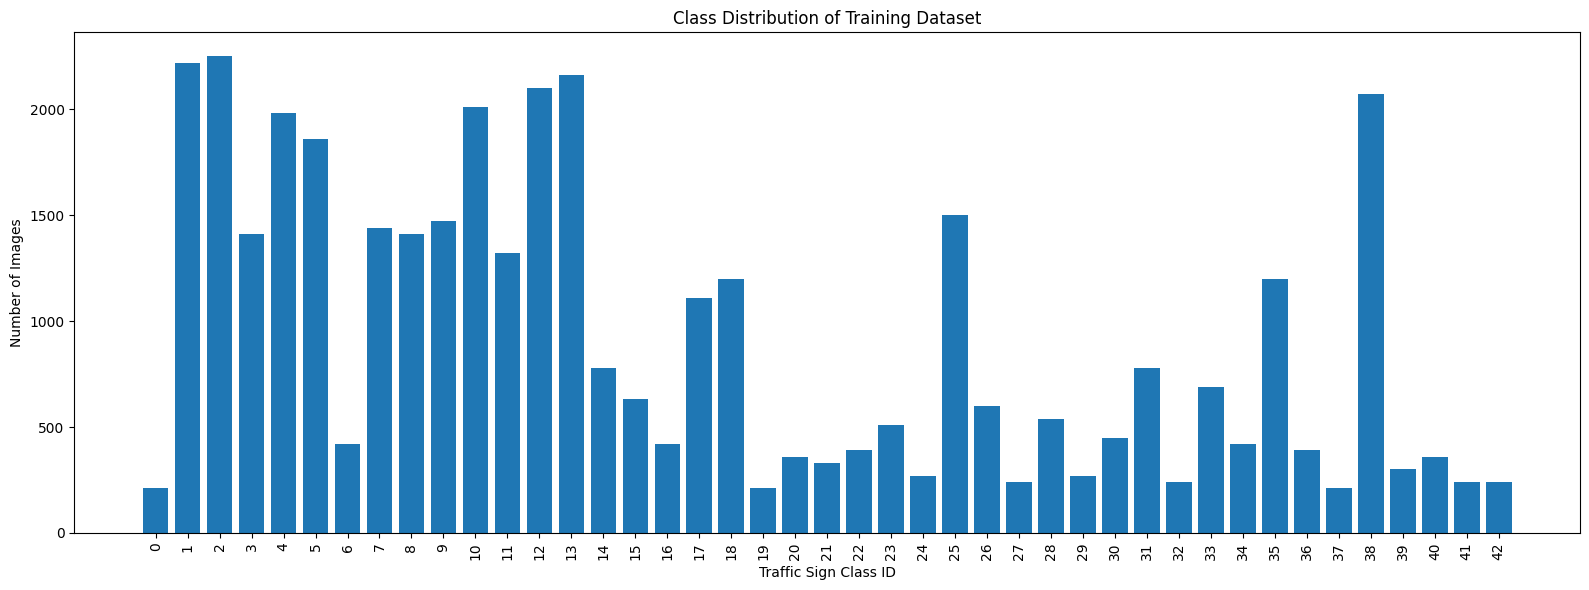

Total training images: 39209
Number of classes: 43
Minimum images in a class: 210
Maximum images in a class: 2250

Images per class:
ClassId
0      210
1     2220
2     2250
3     1410
4     1980
5     1860
6      420
7     1440
8     1410
9     1470
10    2010
11    1320
12    2100
13    2160
14     780
15     630
16     420
17    1110
18    1200
19     210
20     360
21     330
22     390
23     510
24     270
25    1500
26     600
27     240
28     540
29     270
30     450
31     780
32     240
33     689
34     420
35    1200
36     390
37     210
38    2070
39     300
40     360
41     240
42     240


In [19]:

import pandas as pd
import matplotlib.pyplot as plt

# Count images in each traffic sign class
class_counts = train_csv.groupby("ClassId").size().sort_index()

# Create bar chart
plt.figure(figsize=(16, 6))
plt.bar(class_counts.index, class_counts.values)

plt.xlabel("Traffic Sign Class ID")
plt.ylabel("Number of Images")
plt.title("Class Distribution of Training Dataset")
plt.xticks(range(43), rotation=90)
plt.tight_layout()
plt.show()

# Display statistics
print("Total training images:", int(class_counts.sum()))
print("Number of classes:", len(class_counts))
print("Minimum images in a class:", int(class_counts.min()))
print("Maximum images in a class:", int(class_counts.max()))

print("\nImages per class:")
print(class_counts.to_string())


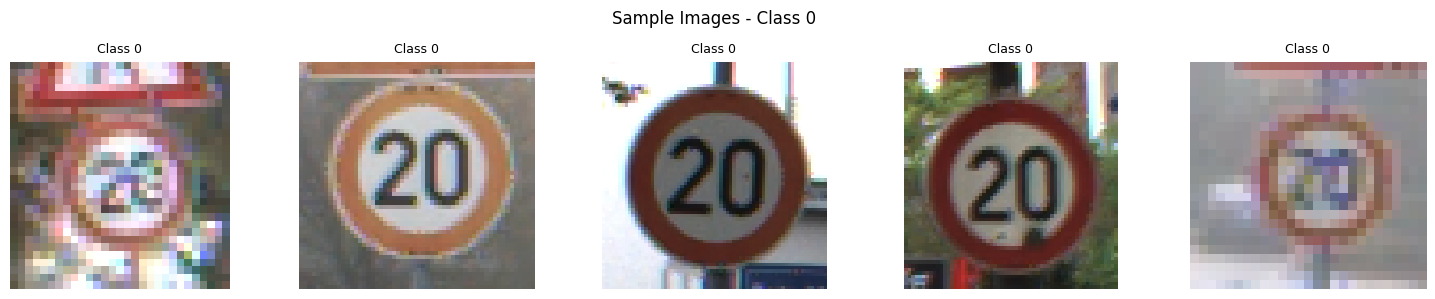

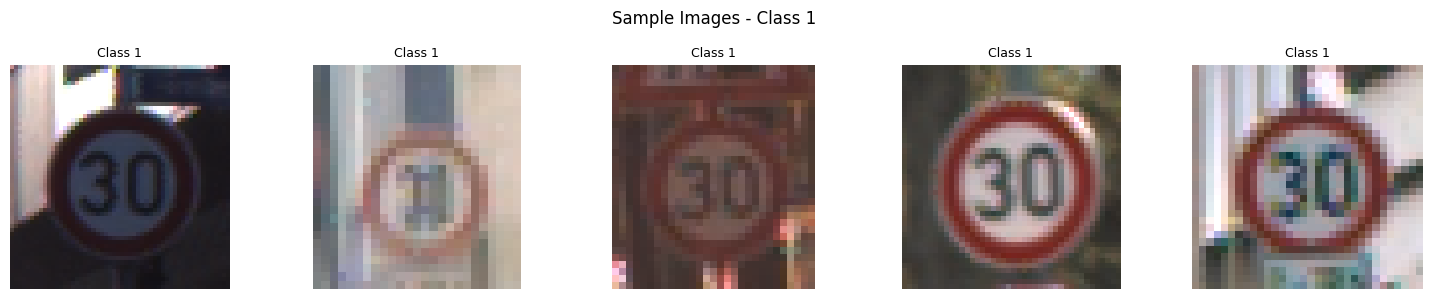

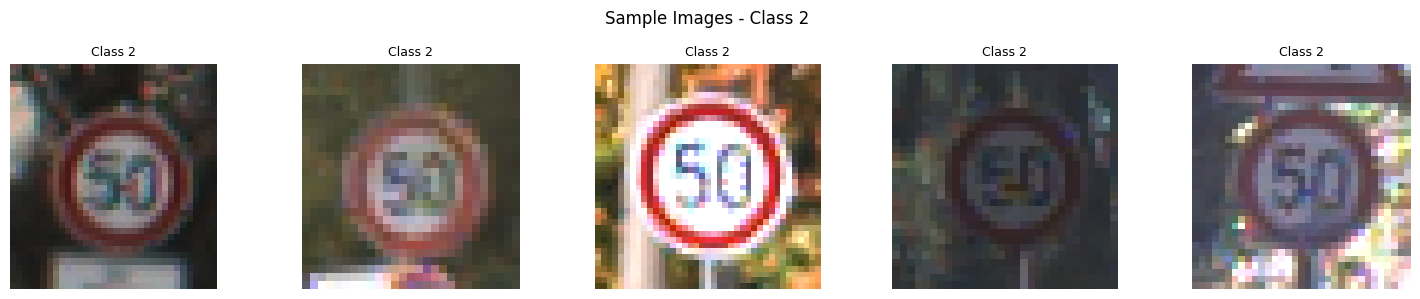

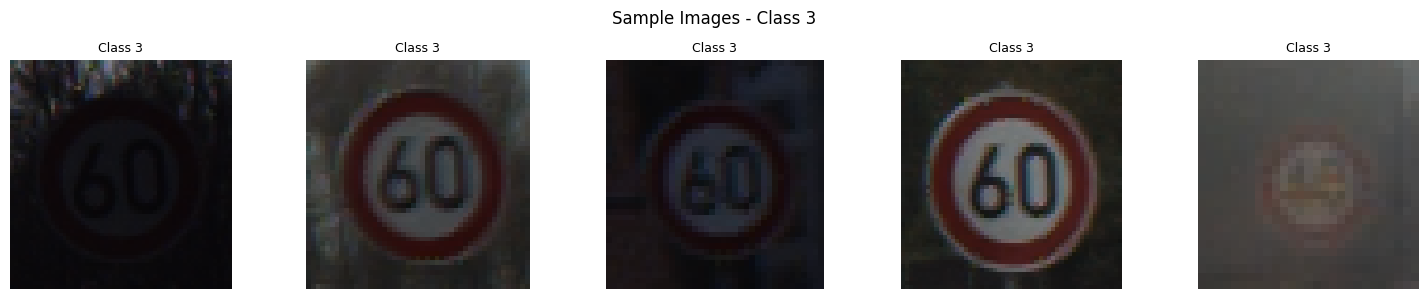

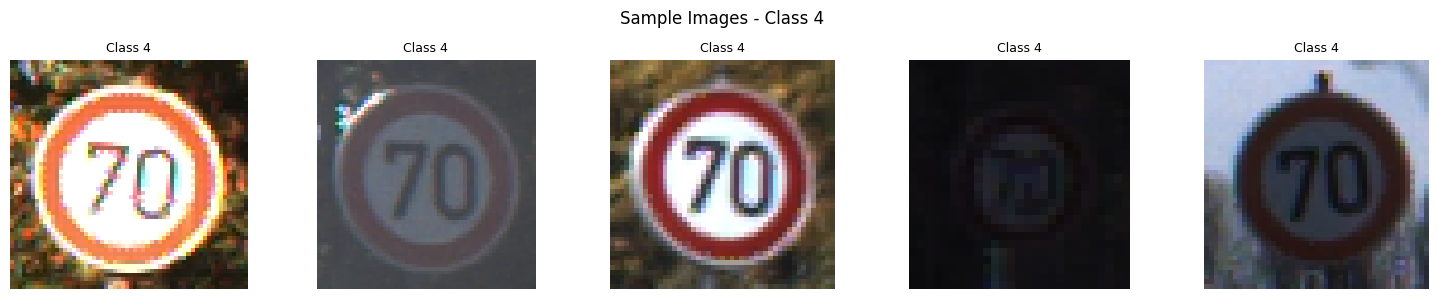

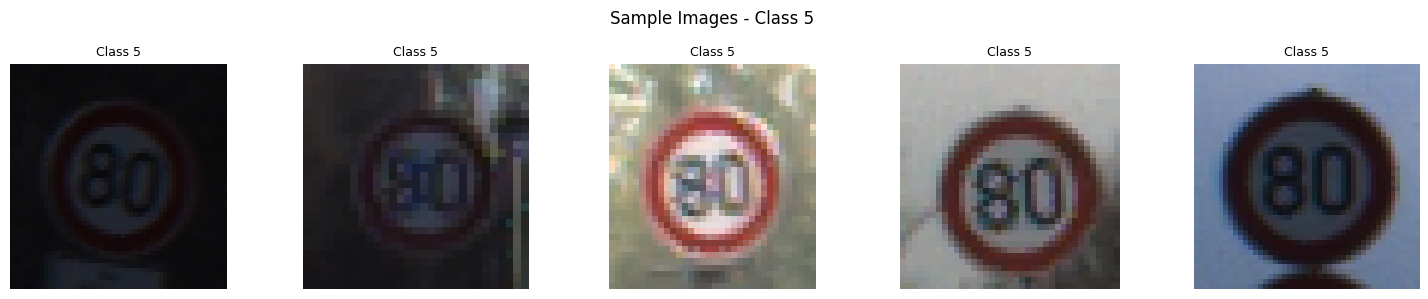

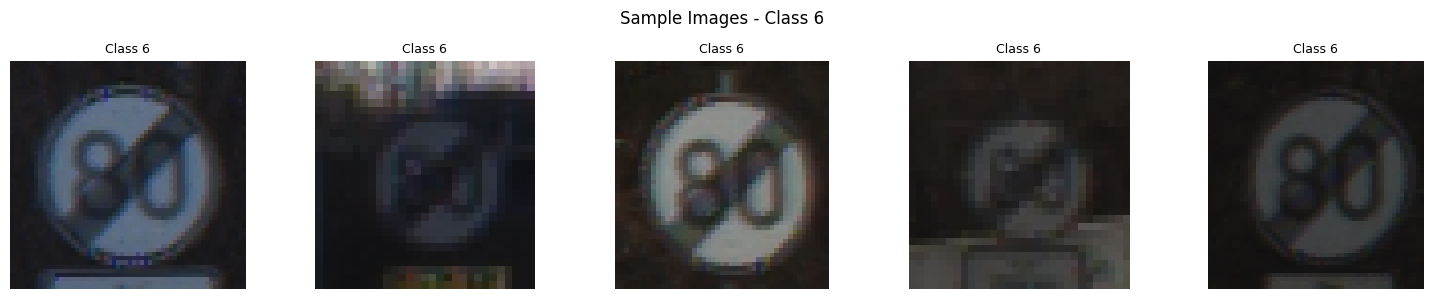

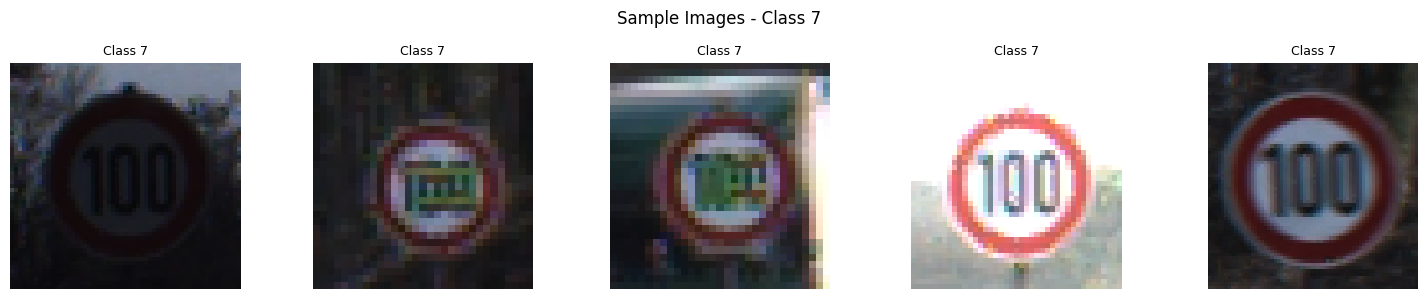

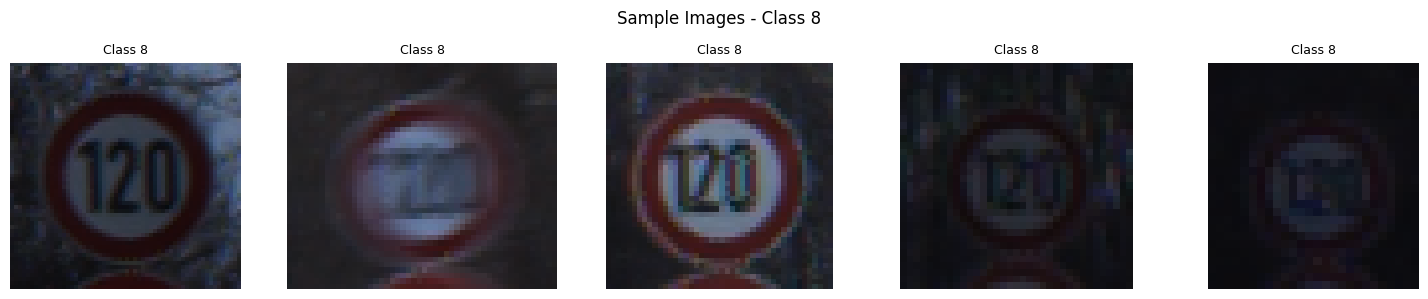

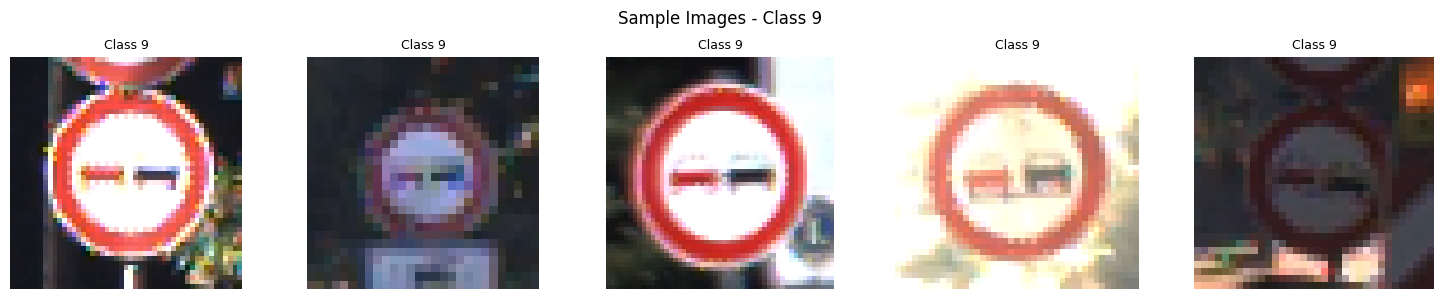

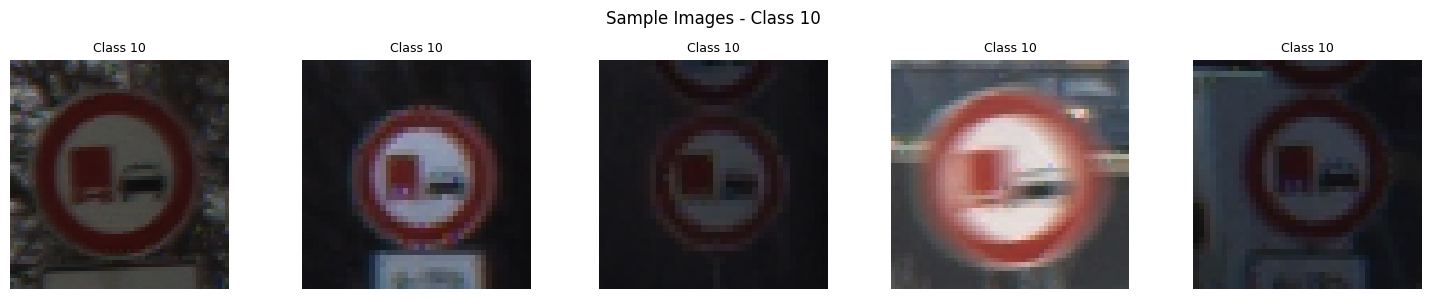

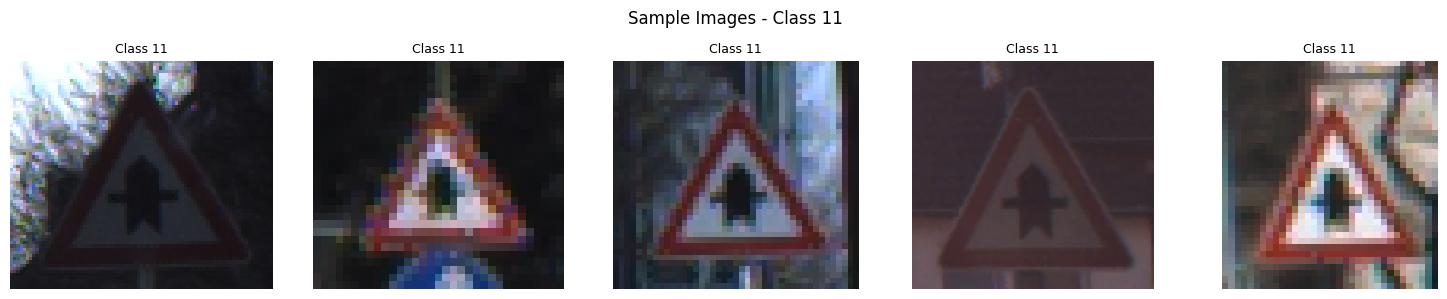

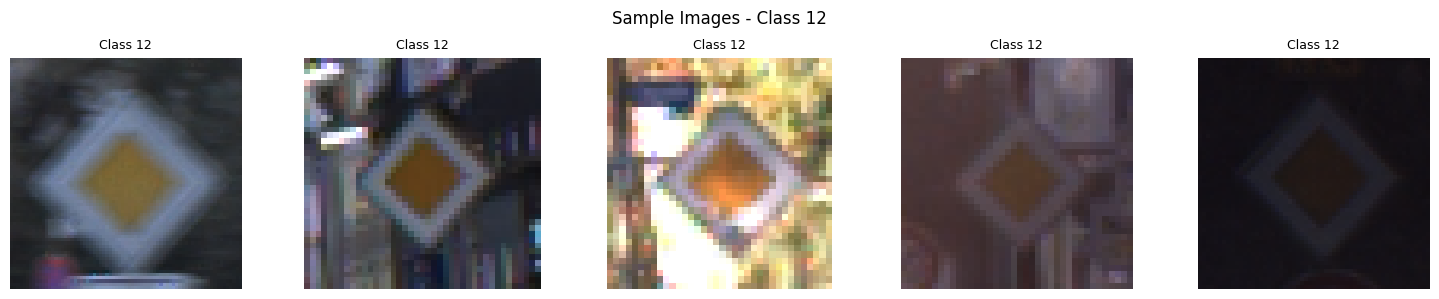

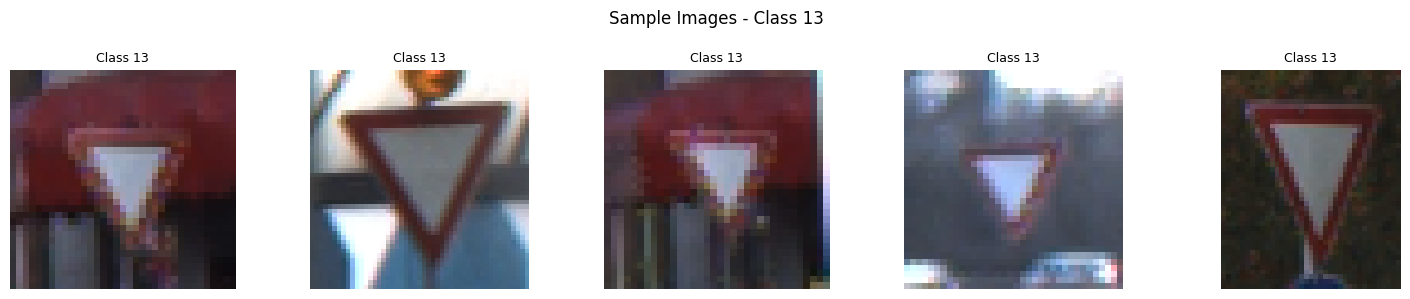

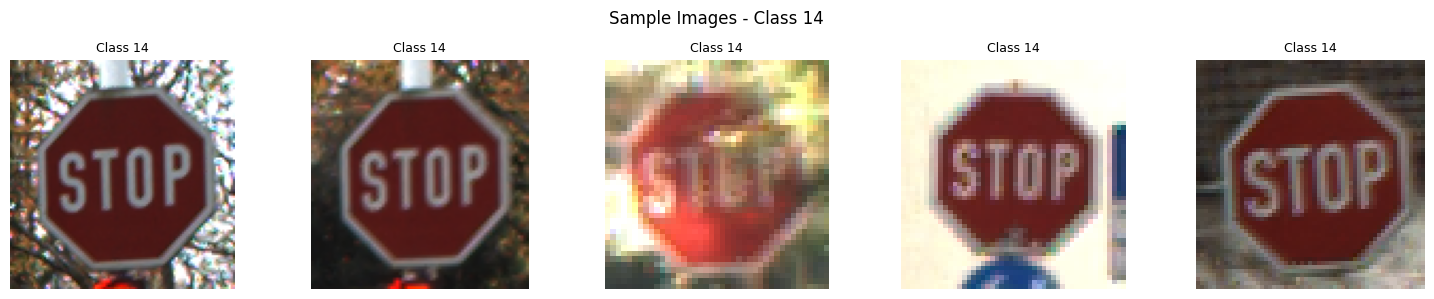

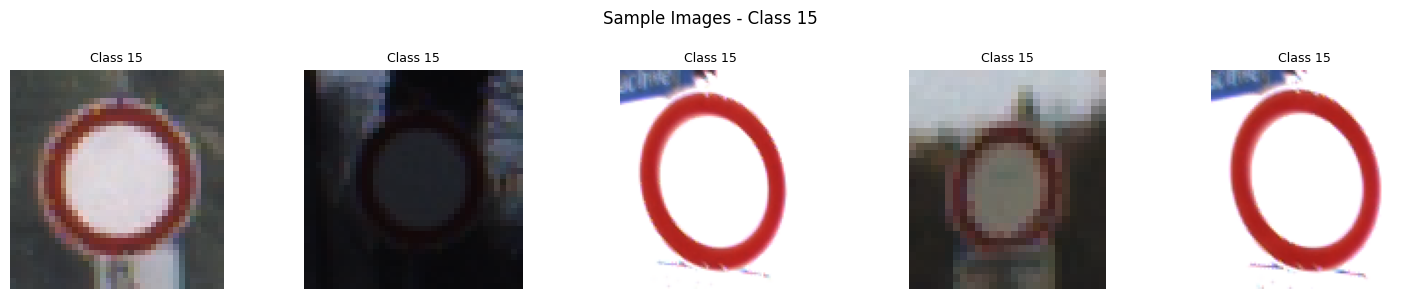

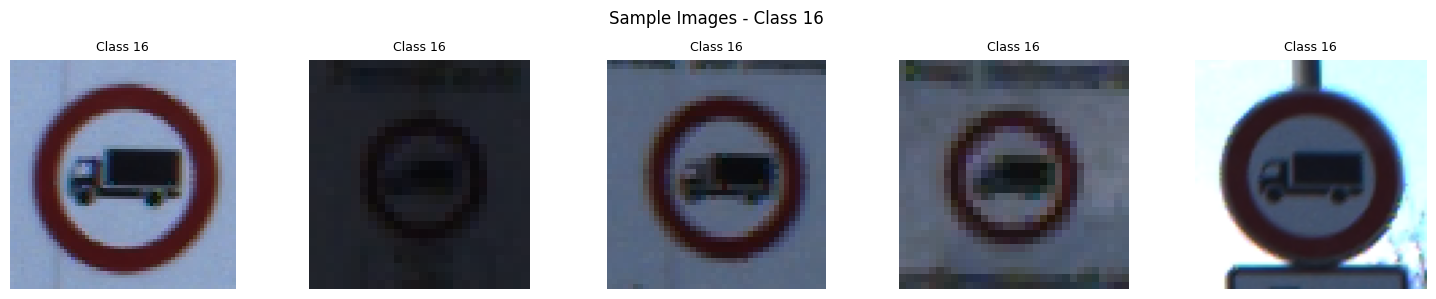

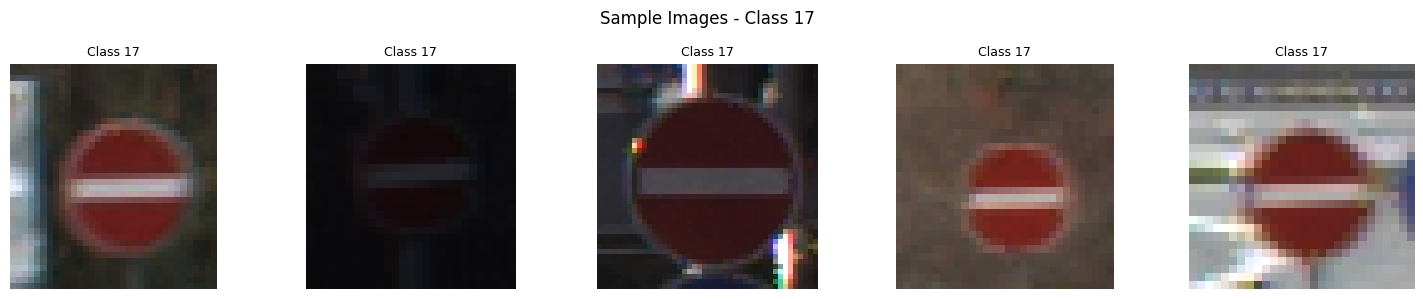

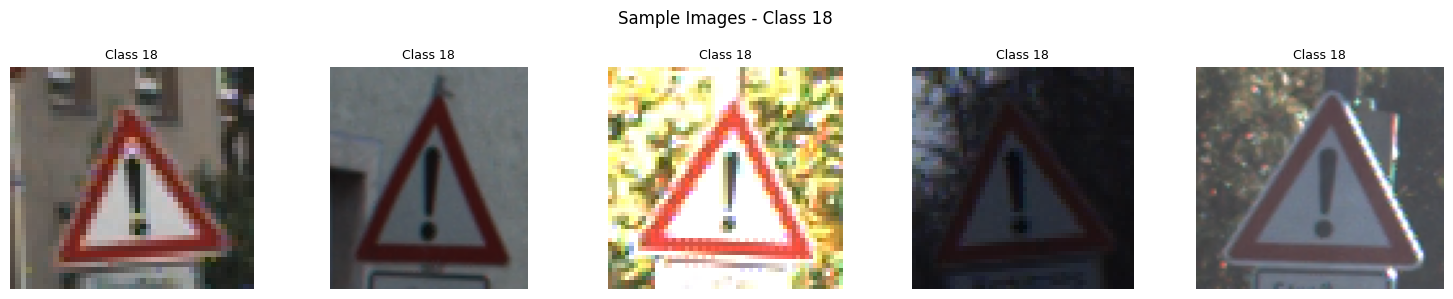

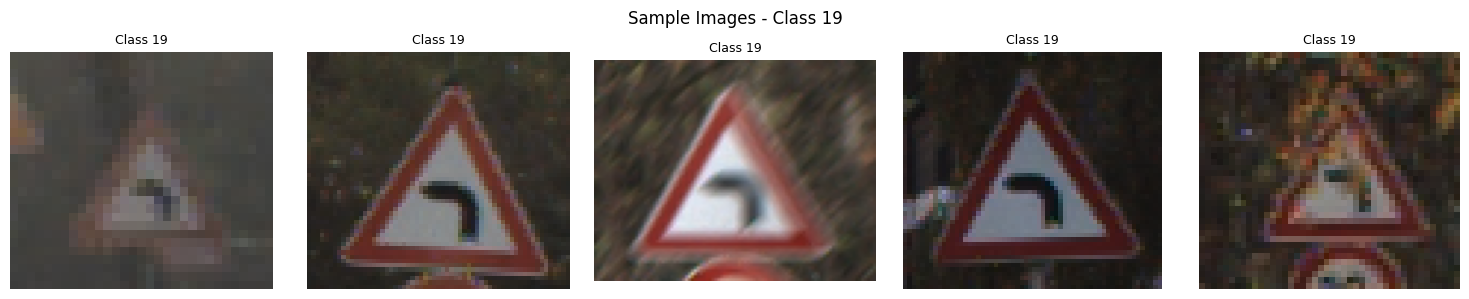

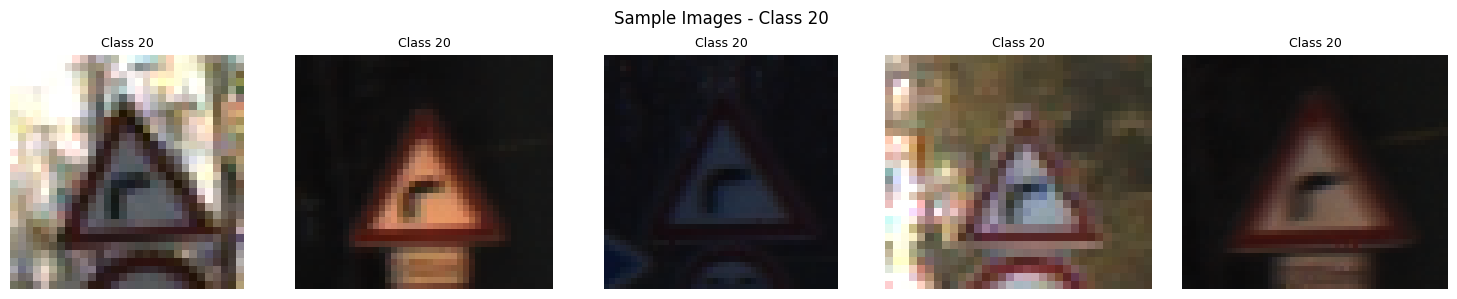

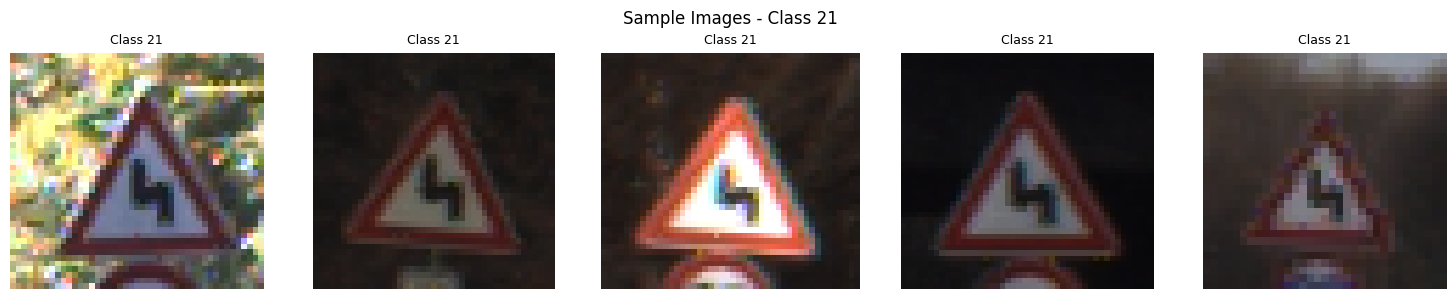

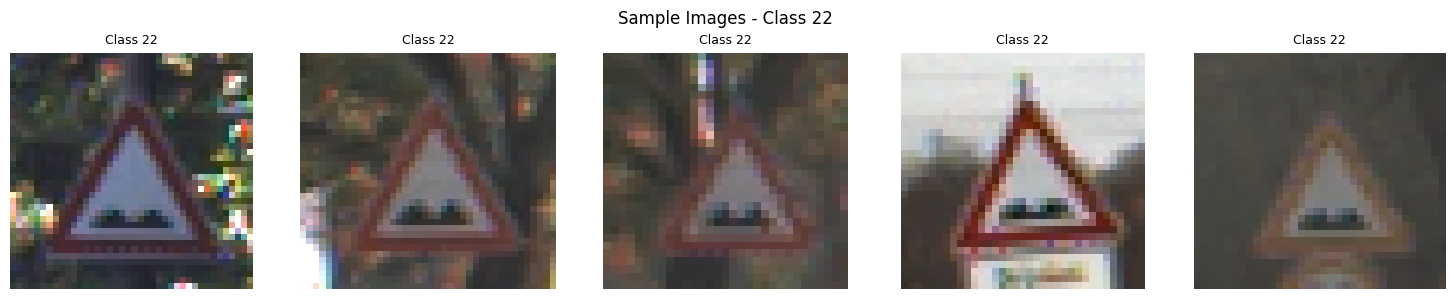

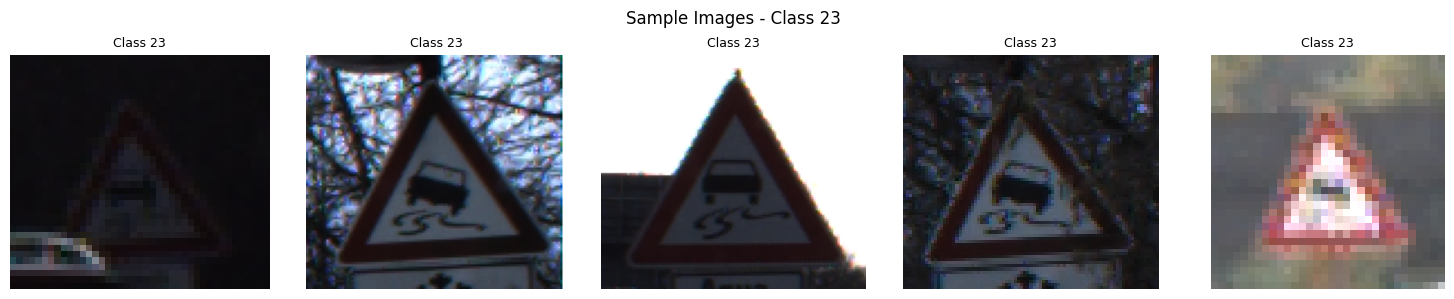

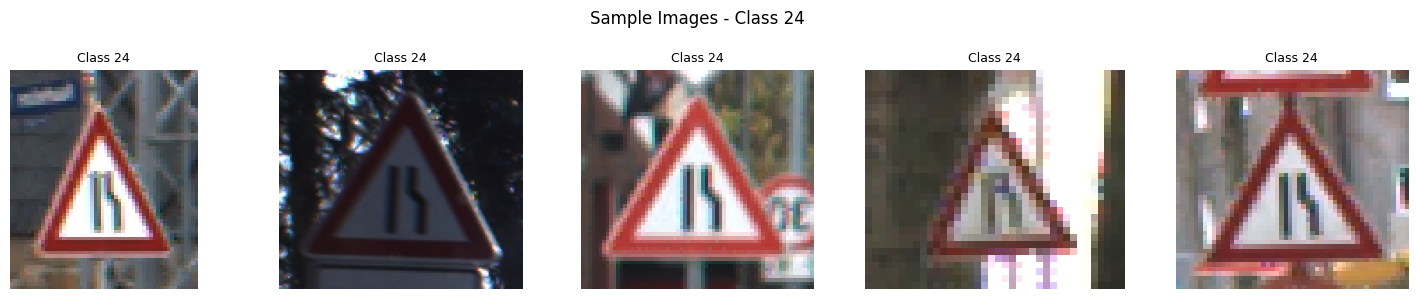

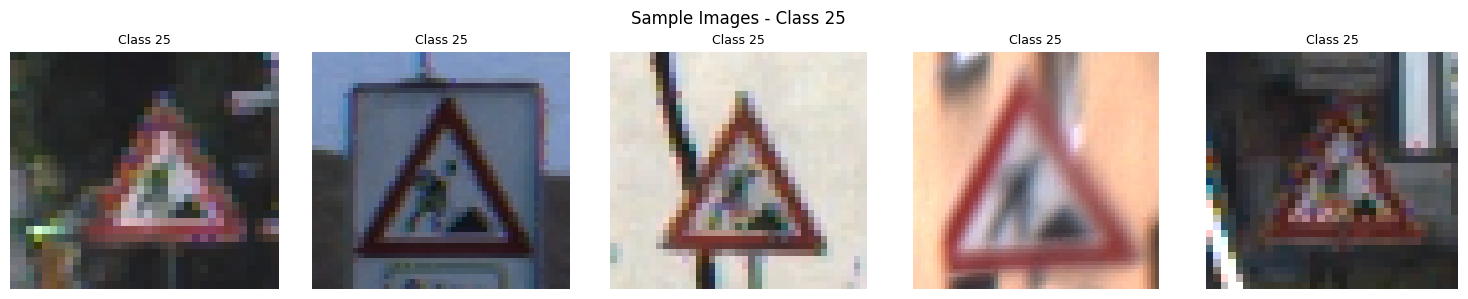

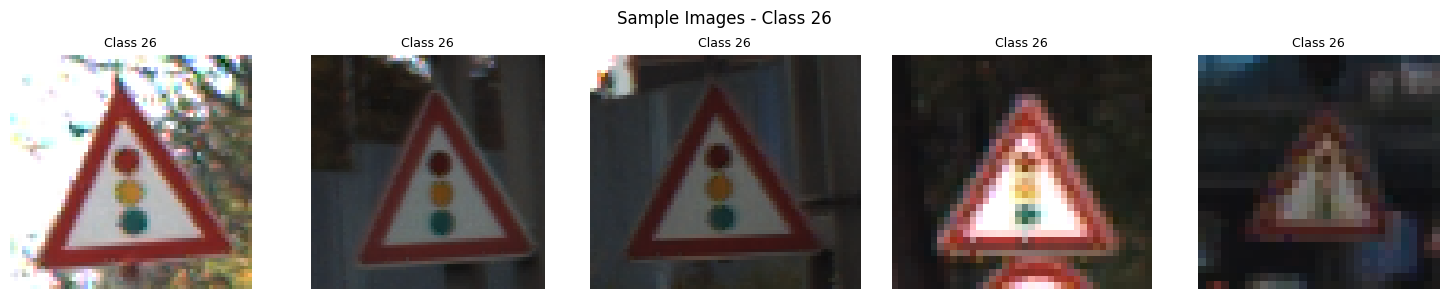

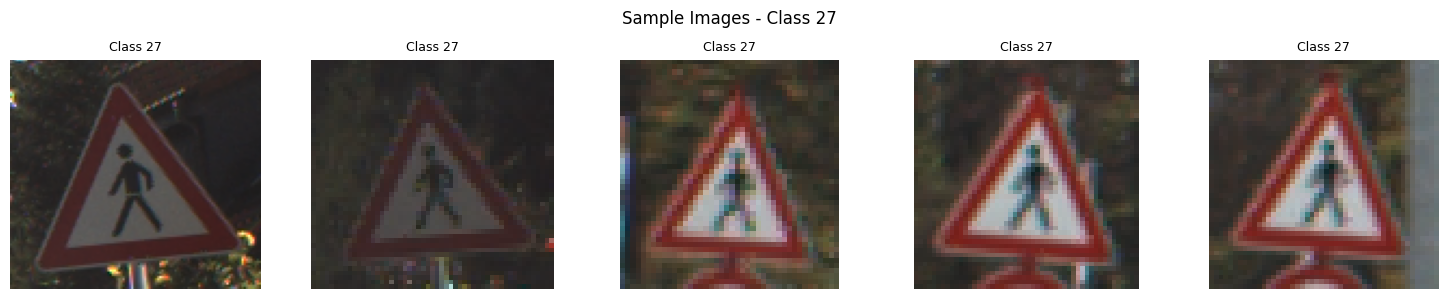

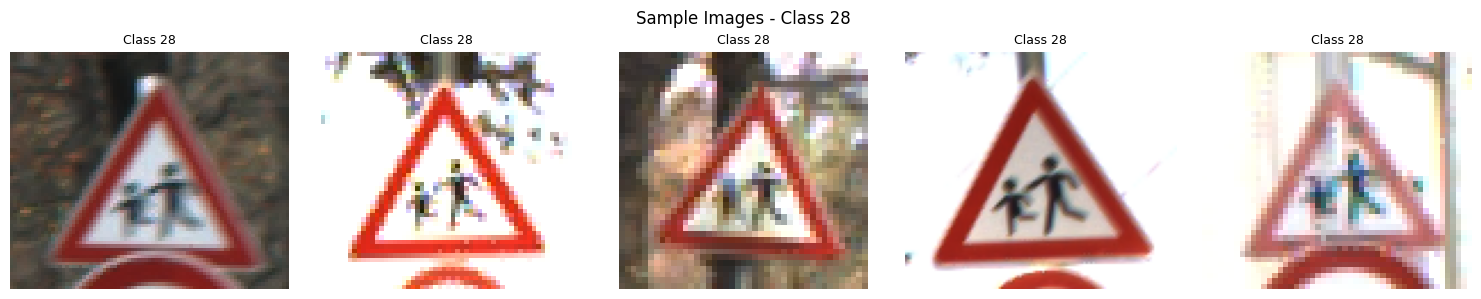

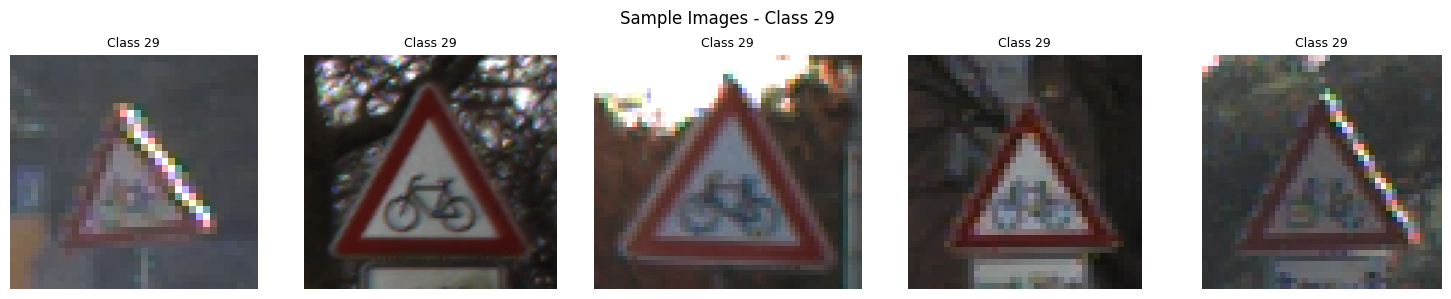

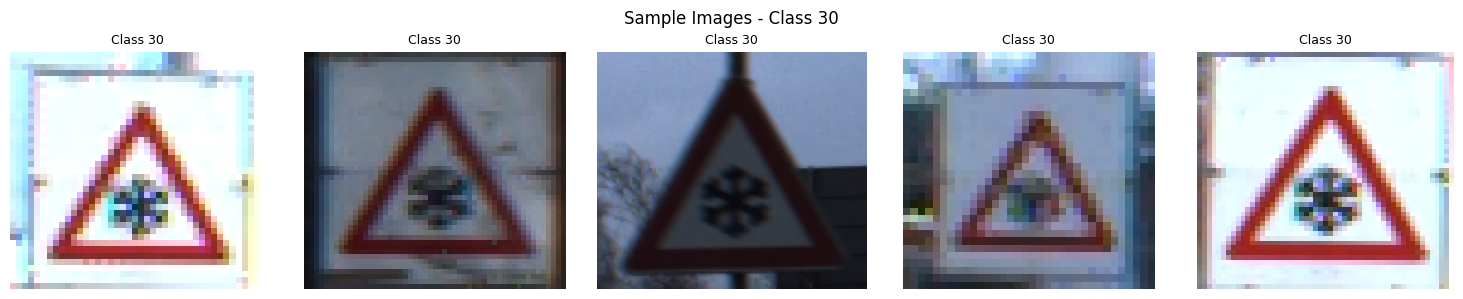

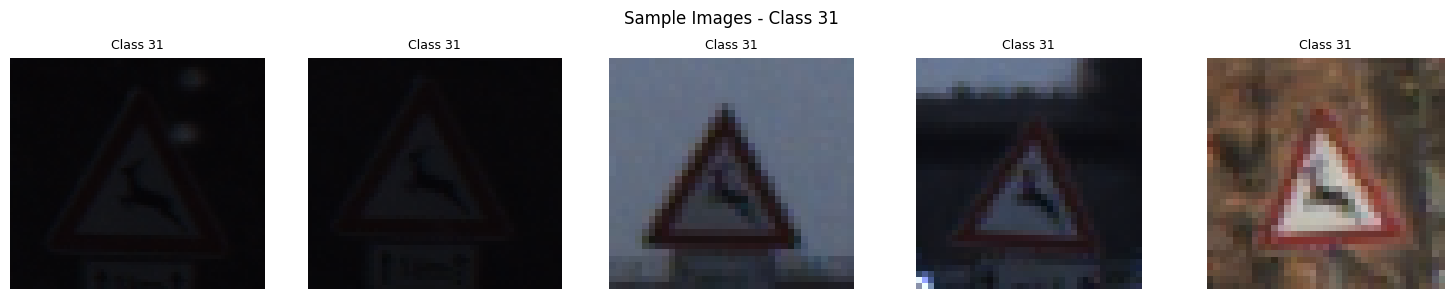

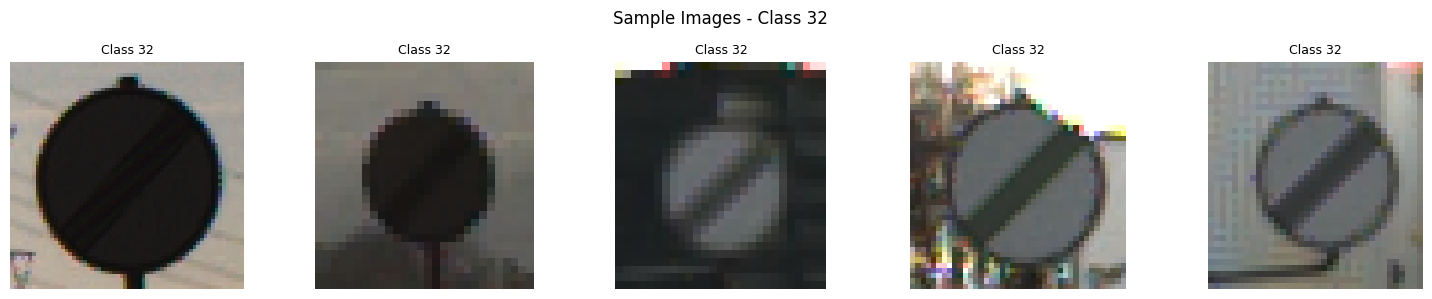

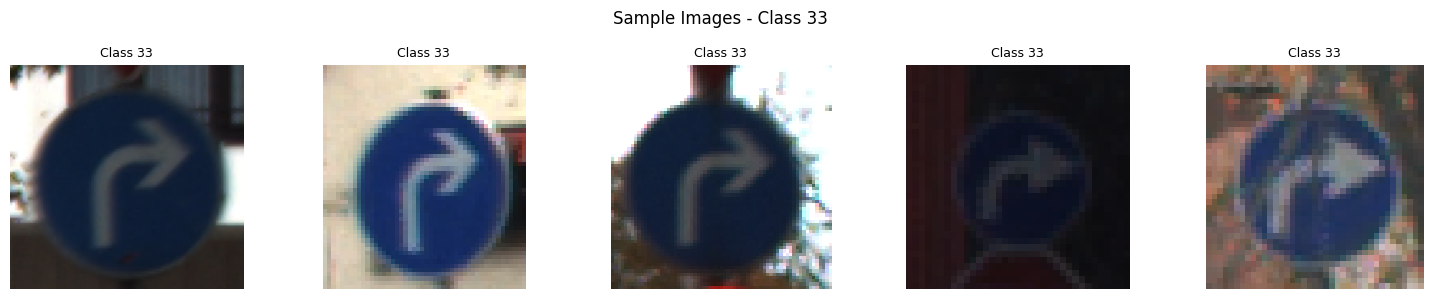

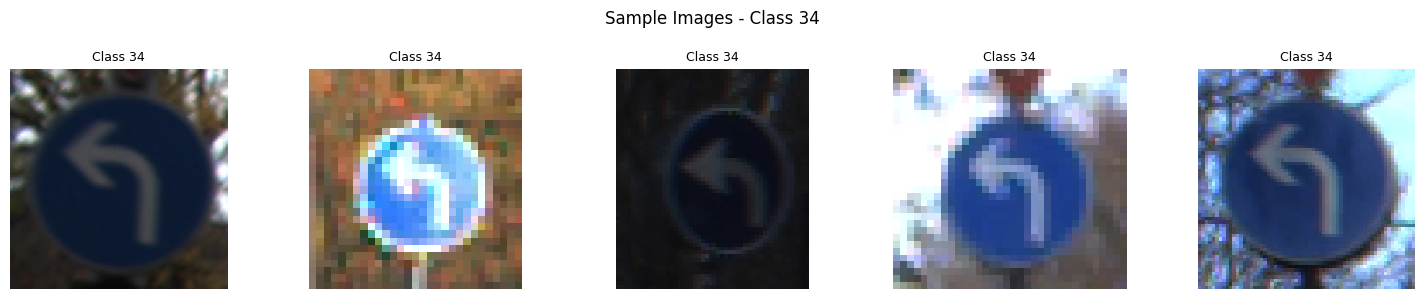

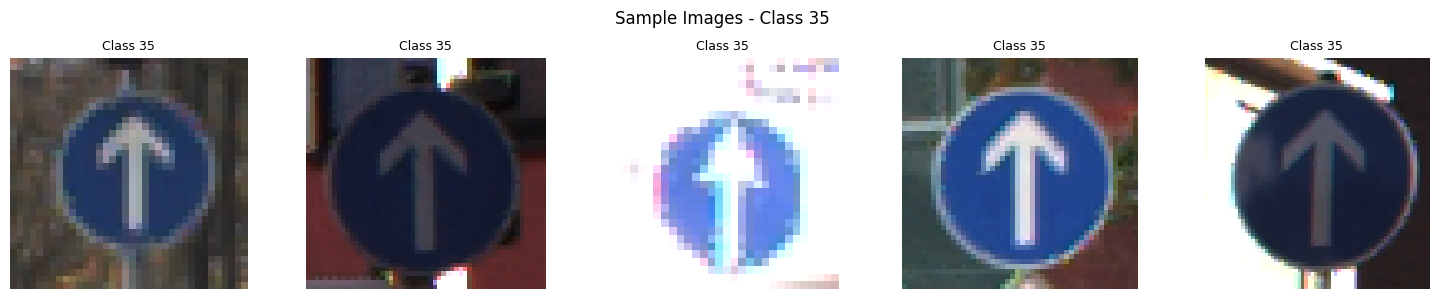

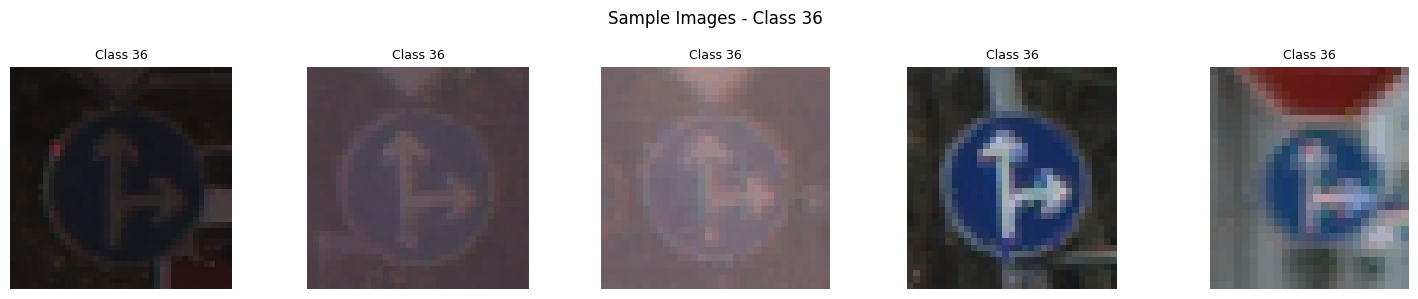

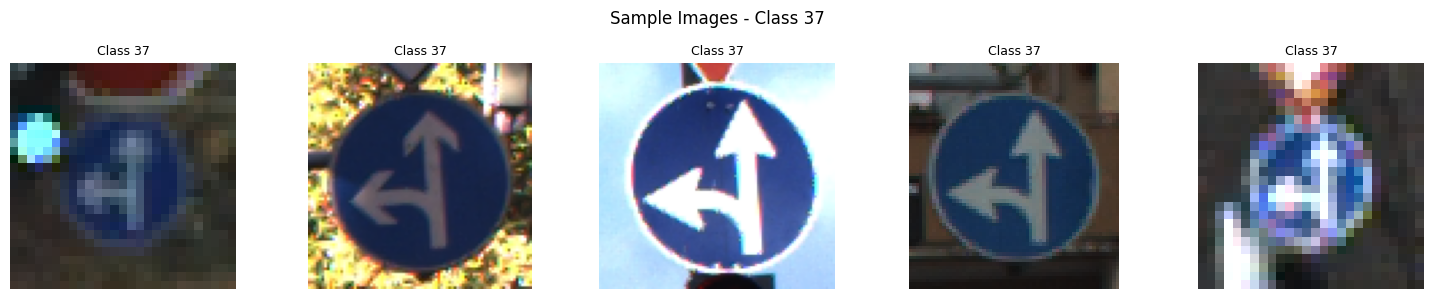

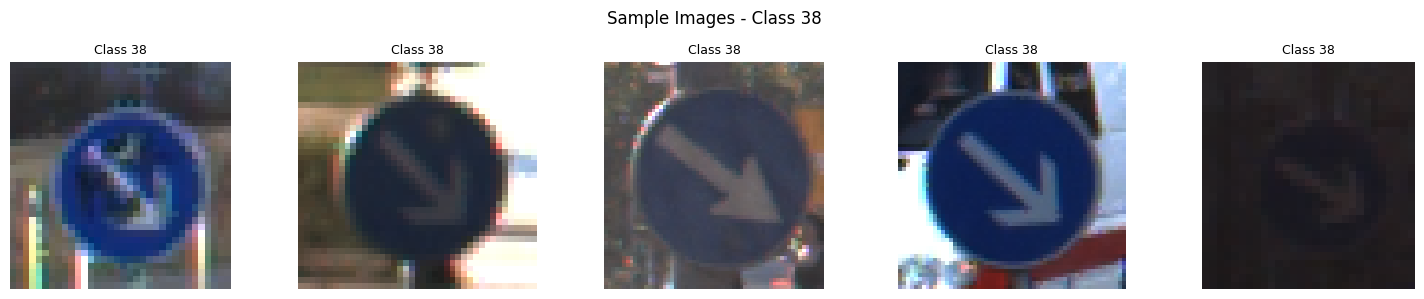

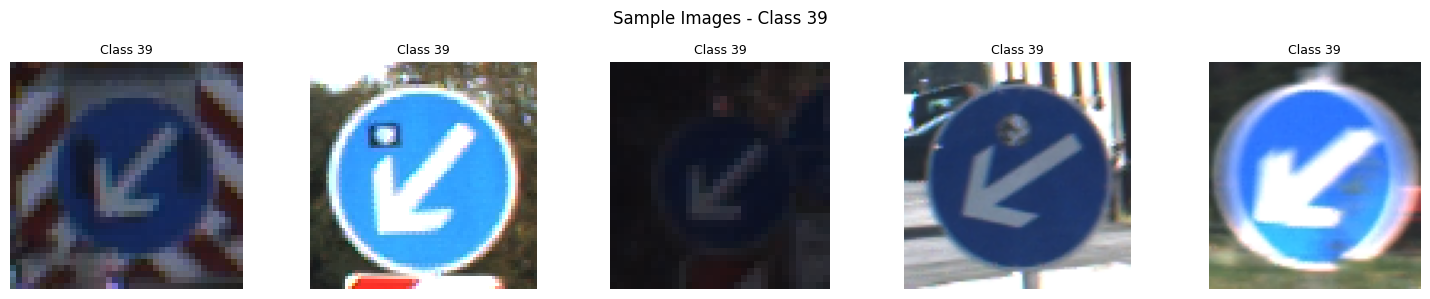

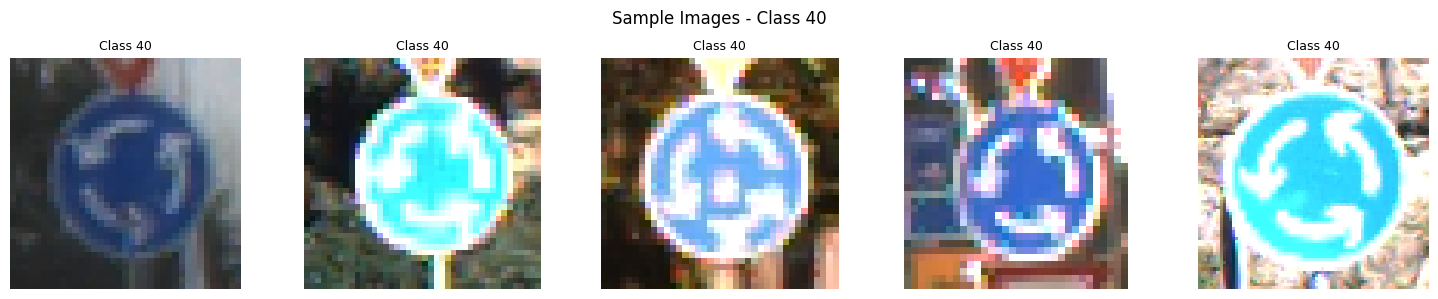

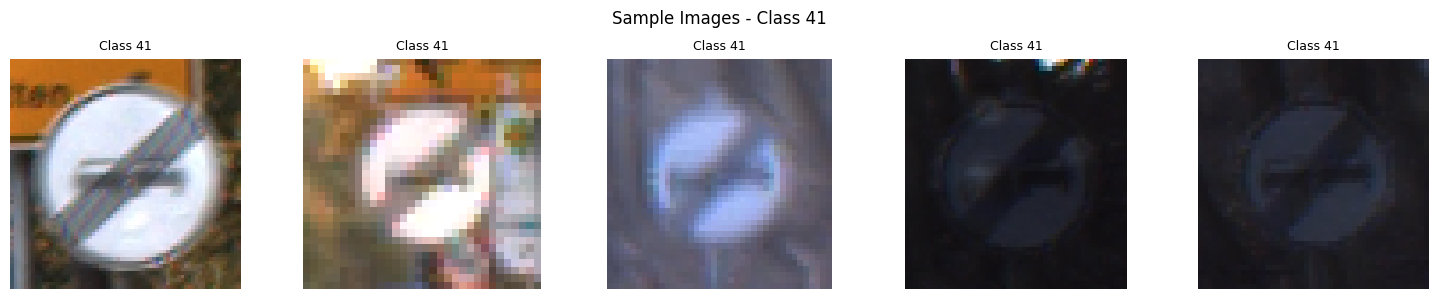

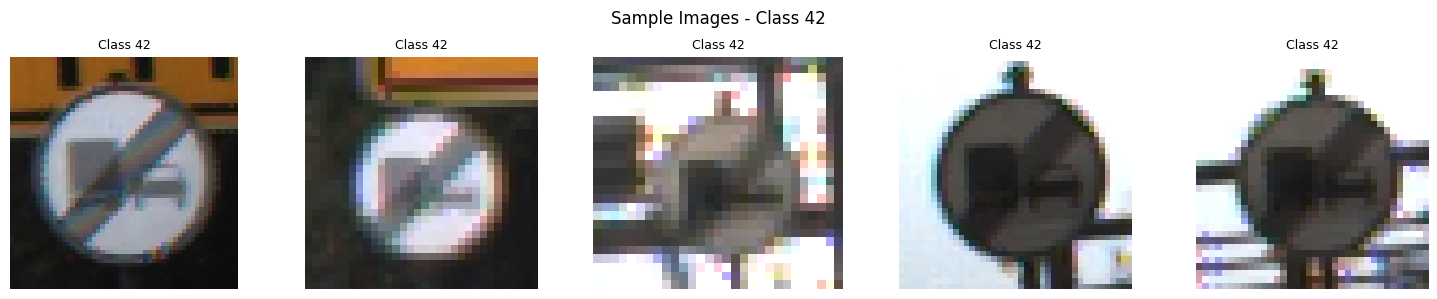

In [20]:

import os
import matplotlib.pyplot as plt
from PIL import Image

extract_path = "/content/traffic_sign_dataset"

# Show 5 sample images from each class
for class_id in sorted(train_csv["ClassId"].unique()):

    class_data = train_csv[train_csv["ClassId"] == class_id]
    samples = class_data.sample(
        n=min(5, len(class_data)),
        random_state=42
    )

    fig, axes = plt.subplots(1, len(samples), figsize=(15, 3))

    if len(samples) == 1:
        axes = [axes]

    for ax, (_, row) in zip(axes, samples.iterrows()):

        # Remove the leading /code/ from the CSV path
        relative_path = row["Path"].lstrip("/")
        if relative_path.startswith("code/"):
            relative_path = relative_path[len("code/"):]

        image_path = os.path.join(extract_path, relative_path)

        try:
            img = Image.open(image_path).convert("RGB")
            ax.imshow(img)
            ax.set_title(f"Class {class_id}", fontsize=9)
            ax.axis("off")
        except Exception as e:
            ax.set_title("Image not found")
            ax.axis("off")
            print("Error loading:", image_path)

    plt.suptitle(f"Sample Images - Class {class_id}")
    plt.tight_layout()
    plt.show()
